# Extended Schelling Model: Marriage, Openness and Cross-Group Households

**CITS4403 Research Project**

Schelling's segregation model shows how mild individual preferences for similar neighbours can produce strongly segregated neighbourhoods. The classic model only lets agents *move*. Real neighbourhoods also change through **household formation**: people pair up, and some pairs cross group lines.

**Our extension.** We add two mechanisms to the textbook Schelling model:

1. **Marriage parameter $m$**: neighbouring single agents who are both satisfied can form two-person households (AA, BB or mixed AB). $m$ sets both the probability that an eligible agent is willing to marry in a given step and the overall cap on the number of marriages.
2. **Openness $o$**: a per-agent trait that sets (i) how likely an agent is to marry across group lines and (ii) how much an agent tolerates neighbours from the other group when judging its satisfaction.

**Research question.** Once agents form households, do mixed AB households act as *connectors* between the two otherwise separated communities, and how do $m$ and openness strengthen or weaken that bridging effect?

## Contents

1. [Setup](#1.-Setup)
2. [Model specification](#2.-Model-specification)
3. [Model testing](#3.-Model-testing)
4. [Initial state and model behaviour](#4.-Initial-state-and-model-behaviour)
5. [Calibrating the satisfaction threshold $p$](#5.-Calibrating-the-satisfaction-threshold-p)
6. [Effect of the marriage parameter $m$ on clustering](#6.-Effect-of-the-marriage-parameter-m-on-clustering)
7. [How $p$ changes the effect of $m$](#7.-How-p-changes-the-effect-of-m)
8. [AB households as connectors: effect of $m$](#8.-AB-households-as-connectors:-effect-of-m)
9. [Effect of openness](#9.-Effect-of-openness)
10. [Interaction between openness and $m$](#10.-Interaction-between-openness-and-m)
11. [Summary and limitations](#11.-Summary-and-limitations)

## 1. Setup

The model classes (`Person`, `Schelling`) are in `src/extended_schelling.py`. `Schelling` builds on the `Cell2D` base class, and the plotting helpers (`decorate`, `three_frame`, `number_frame`, `set_palette`) are in `utils/`. Run this notebook from the `notebooks/` folder after installing `requirements.txt` (see `README.md`).

> **Runtime note.** Most experiments repeat 100 × 100 simulations for 100–200 steps over several seeds. Sections 5–9 can each take several minutes; Section 9 (300 runs) is the slowest.

In [1]:
# Make the model (src/) and helper modules (utils/) importable from notebooks/
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for folder in ("src", "utils"):
    sys.path.insert(0, str(ROOT / folder))

# Libraries used in this notebook
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage
from scipy.signal import correlate2d
from empiricaldist import Cdf
from utils import number_frame, decorate
from matplotlib.colors import ListedColormap

# The extended model (src/extended_schelling.py)
from extended_schelling import Schelling


## 2. Model specification

**Grid and states.** The model runs on an $n \times n$ grid ($n = 100$) with a toroidal (wrap-around) boundary. Each cell is in one of six states:

| Value | State | Value | State |
|---|---|---|---|
| 0 | empty | 3 | AA couple |
| 1 | single A | 4 | BB couple |
| 2 | single B | 5 | AB (mixed) couple |

**Initialisation.** Each cell is empty with probability 0.1, and single A or single B with probability 0.45 each. Every agent draws an openness $o_i$ uniformly from $\{0.1, 0.2, \dots, 0.9\}$, unless `fixed_openness` is set, in which case every agent (including agents created later) gets that value.

**Neighbourhood counts.** For each cell, the 8-cell Moore neighbourhood gives $n_A$ (pure-A neighbours: A or AA), $n_B$ (pure-B neighbours: B or BB) and $n_{AB}$ (AB neighbours), with $N = n_A + n_B + n_{AB}$.

**Satisfaction.** Each occupant computes a satisfaction score $S$ (and $S = 0$ if $N = 0$):

$$S_{A} = \frac{n_A + n_{AB} + o_i\,n_B}{N}, \qquad S_{B} = \frac{n_B + n_{AB} + o_i\,n_A}{N}$$

$$S_{AA} = \frac{n_A + n_{AB}}{N}, \qquad S_{BB} = \frac{n_B + n_{AB}}{N}, \qquad S_{AB} = \frac{1.5\,n_{AB} + o_i\,(n_A + n_B)}{N}$$

An occupant is **happy** if $S \ge p$, where $p$ is the satisfaction threshold.

**One time step** (`Schelling.step`):

1. Compute satisfaction for every occupant.
2. **Relocation**: unhappy occupants, in random order, move to a randomly chosen empty cell.
3. Recompute satisfaction and update how many consecutive rounds each pair of agents has been neighbours.
4. **Marriage** (while fewer than $\lfloor m \cdot N_0 \rfloor$ marriages have occurred, where $N_0$ is the initial number of agents):
   - *Eligible pairs*: two **happy singles** who have been neighbours for at least **3 consecutive rounds**.
   - Each agent in an eligible pair is *willing* this step with probability $m$; only pairs where both are willing remain.
   - Pairs are drawn one at a time without reusing anyone, with weight $w = 1$ for a same-group pair and $w = o_i \, o_j$ for a cross-group pair.
5. **Household formation**: one of the two cells (chosen 50/50) becomes the couple (AA, BB or AB); the other cell becomes a **new single** of the same group (for AB, A or B with probability ½) with a newly drawn openness. An AB couple's openness is $\min(o_i, o_j)$. The number of occupied cells therefore stays constant.

**Outcome measures used below.**

- **Segregation**: the mean, over occupied cells, of the fraction of occupied neighbours of the same type (`Schelling.segregation`).
- **Average cluster size**: the number of pure-A (or pure-B) cells divided by the number of 8-connected clusters they form.
- **AB boundary fraction**: the share of AB households with at least one pure-A *and* at least one pure-B neighbour:

$$\text{boundary fraction} = \frac{\#\{\text{AB cells with } n_A > 0 \text{ and } n_B > 0\}}{\#\{\text{AB cells}\}}$$

## 3. Model testing

Before analysing the results, we check whether the model follows its rules. Each check shows PASS or FAIL.

### Initialization checks

We check the initial cell states, agent records, unique IDs, marriage limit, and marriage counter.

In [2]:
grid = Schelling(n=100, p=0.4)
checks = grid.check_initialization()

for name, passed in checks.items():
    if passed: print(f"PASS: {name}")
    else: print(f"FAIL: {name}")

print(f"Empty cells: {np.mean(grid.array == 0):.1%} " "(expected: about 10%)")

PASS: Only initial states (0, 1, 2)
PASS: Population matches occupied cells
PASS: Unique agent IDs
PASS: Grid and agent records agree
PASS: ID lookup agrees with agent records
PASS: Marriage limit is correct
PASS: No marriages yet
Empty cells: 9.5% (expected: about 10%)


### Initial openness checks

We check that random openness values use the nine levels from 0.1 to 0.9. We then set openness to 0.8 and check that every initial agent receives this value.

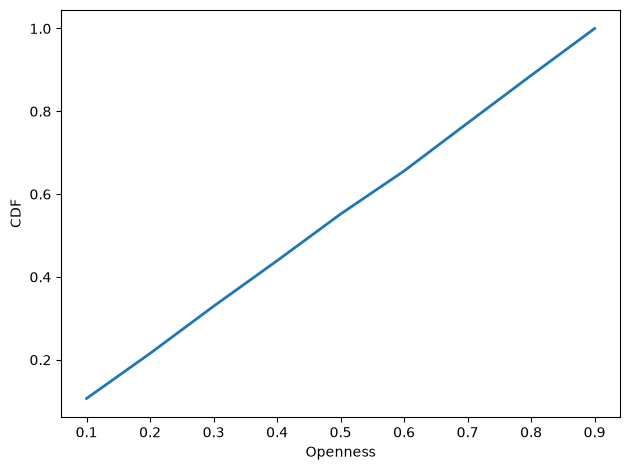

In [3]:
grid = Schelling(n=100, p=0.4)
cdf = Cdf.from_seq(person.openness for person in grid.people.values())

cdf.plot()
decorate(xlabel='Openness', ylabel='CDF')

The CDF shows the proportion of agents with openness at or below each value. Its nearly linear shape reflects approximately equal frequencies across the nine initial openness levels (0.1–0.9).
### Satisfaction and happiness checks

We use a fixed 5 × 5 grid with openness set to 0.4 and p set to 0.6. We compare the scores of A, B, AA, BB and AB with answers calculated by hand. PASS means both the score and the happiness decision are correct.

In [14]:
# 0 = empty, 1 = A, 2 = B
# 3 = AA, 4 = BB, 5 = AB
initial_layout = [
    [1, 2, 0, 1, 1],
    [0, 1, 5, 1, 1],
    [1, 4, 3, 5, 0],
    [2, 1, 2, 1, 1],
    [2, 2, 1, 2, 2]]

# Create a new model using this layout
test_grid = Schelling(n=5, p=0.6,m=0.0, fixed_openness=0.4, initial_layout=initial_layout)

# Expected scores calculated by hand
expected_scores = {
    (1, 1): (3 + 1 + 0.4 * 2) / 6,  # A
    (3, 2): (3 + 1 + 0.4 * 4) / 8,  # B
    (2, 2): (4 + 2) / 8,             # AA
    (2, 1): (2 + 1) / 7,             # BB
    (2, 3): (1.5 + 0.4 * 6) / 7      # AB
}

checks = test_grid.check_satisfaction(expected_scores)

group_names = {1: "A", 2: "B", 3: "AA", 4: "BB", 5: "AB"}

rows = []

for loc, expected in expected_scores.items():
    info = test_grid.people[loc].get_info()
    passed = (checks[f"Satisfaction at {loc}"] and checks[f"Happiness at {loc}"])

    rows.append({
        "Type": group_names[info["group"]],
        "Expected score": expected,
        "Actual score": info["satisfaction"],
        "Happy": info["happy"],
        "Result": "PASS" if passed else "FAIL"
    })

display(pd.DataFrame(rows).round(2))

,Type,Expected score,Actual score,Happy,Result
0,A,0.80,0.80,True,PASS
1,B,0.70,0.70,True,PASS
2,AA,0.75,0.75,True,PASS
3,BB,0.43,0.43,False,PASS
4,AB,0.56,0.56,False,PASS


## 4. Initial-state-and-model-behaviour
### Grid evolution

Four snapshots of the same run ($p = 0.7$, $m = 0.3$), taken after 0, 2, 5 and 10 steps (`number_frame` runs 0, 2, 3 and 5 further steps before each frame). Light red and light blue are single A and B agents; dark red (AA), dark blue (BB) and purple (AB) are couples. Couples only appear after neighbours have stayed together for three rounds.

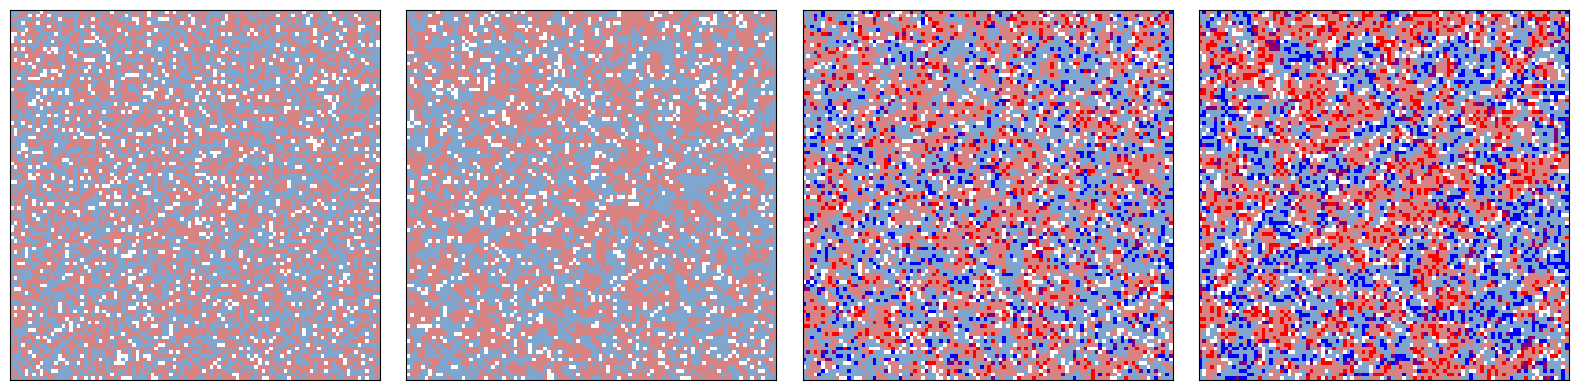

In [35]:
grid = Schelling(n=100, p=0.7, m=0.3)
number_frame(grid,[0,2,3,5],4)

### Animation

An animation of a new run with the same parameters (50 frames, one step between frames). The next cell summarises the final grid of this run.

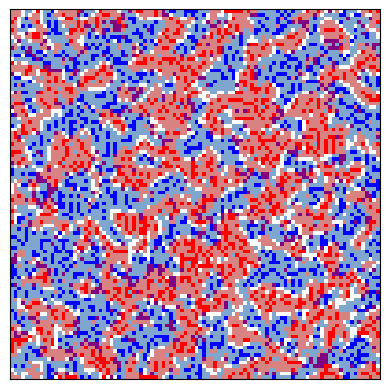

In [36]:
grid = Schelling(n=100, p=0.7, m=0.3)
grid.animate(frames=50, interval=0.1)

### Household composition of a final grid

The title of the plot reports how many cells are single A, single B, AA, BB and AB.

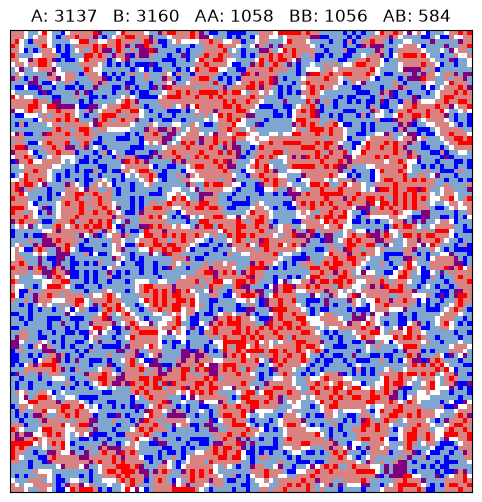

In [37]:
count_a = np.sum(grid.array == 1)
count_b = np.sum(grid.array == 2)
count_aa = np.sum(grid.array == 3)
count_bb = np.sum(grid.array == 4)
count_ab = np.sum(grid.array == 5)

plt.figure(figsize=(6, 6))
grid.draw()
plt.title(
    f"A: {count_a}   B: {count_b}   AA: {count_aa}   "
    f"BB: {count_bb}   AB: {count_ab}"
)
plt.show()

## 5. Calibrating the satisfaction threshold $p$

Before studying marriage and openness, we choose a value of $p$ for the rest of the analysis. These runs use the default marriage parameter $m = 0.1$ and seed 17 (the fine search in Figure 4 uses five seeds).

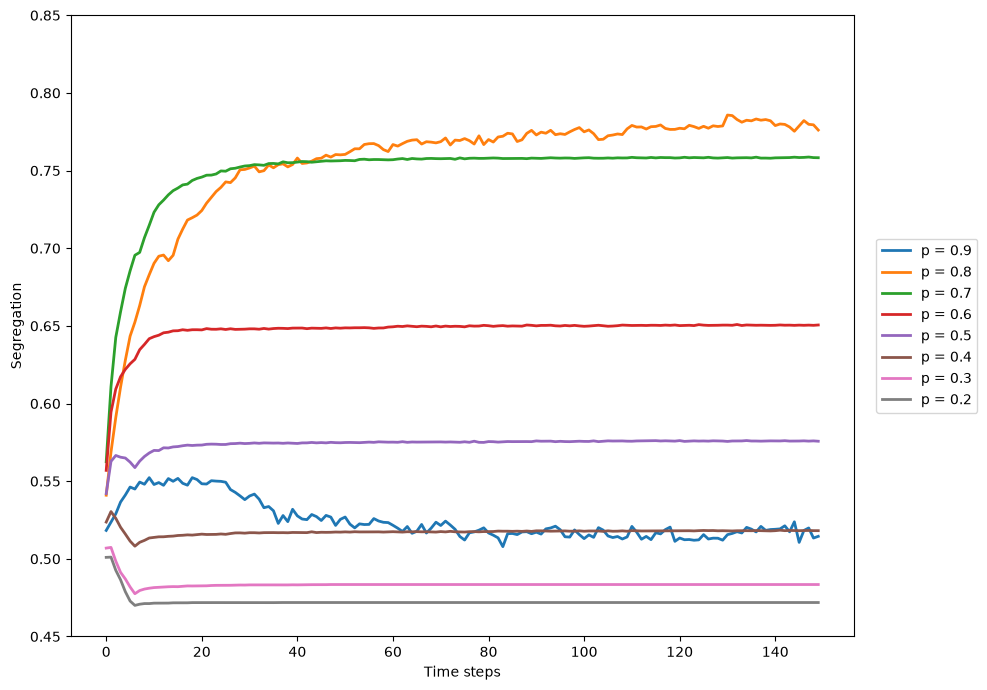

In [38]:
plt.figure(figsize=(10, 7))

for i, p in enumerate([0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]):

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(
        segs,
        label='p = %.1f' % p
    )

decorate(
    xlabel='Time steps',
    ylabel='Segregation', # Segregation: for each agent, the fraction of its occupied neighbours in the same group, averaged over all agents.
    ylim=[0.45, 0.85]
)

# Place the legend outside the plot on the right
plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

### Figure 1: Overall trends for $p=0.2$ to $0.9$

Segregation generally increases as the satisfaction threshold $p$ rises from 0.2 to 0.8. At $p=0.9$, segregation is lower and continues to fluctuate. A possible reason is that many agents remain unhappy under this high threshold, so they keep moving to random empty homes.

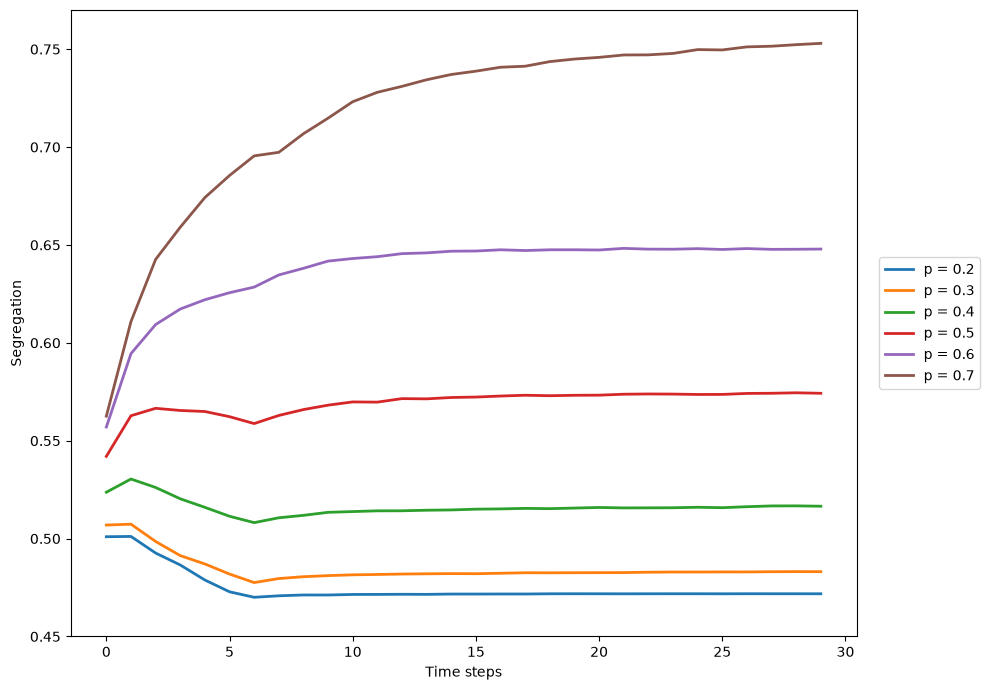

In [39]:
plt.figure(figsize=(10, 7))

for p in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(30)]

    plt.plot(segs, label='p = %.1f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.45, 0.77)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

### Figure 2: Time to settle for $p=0.2$ to $0.7$

At low thresholds ($p=0.2$–$0.4$), segregation changes little after the first few steps. Higher thresholds take longer to reach a nearly stable level. For $p=0.6$ and $p=0.7$, the curves become flatter after about 15–30 time steps.

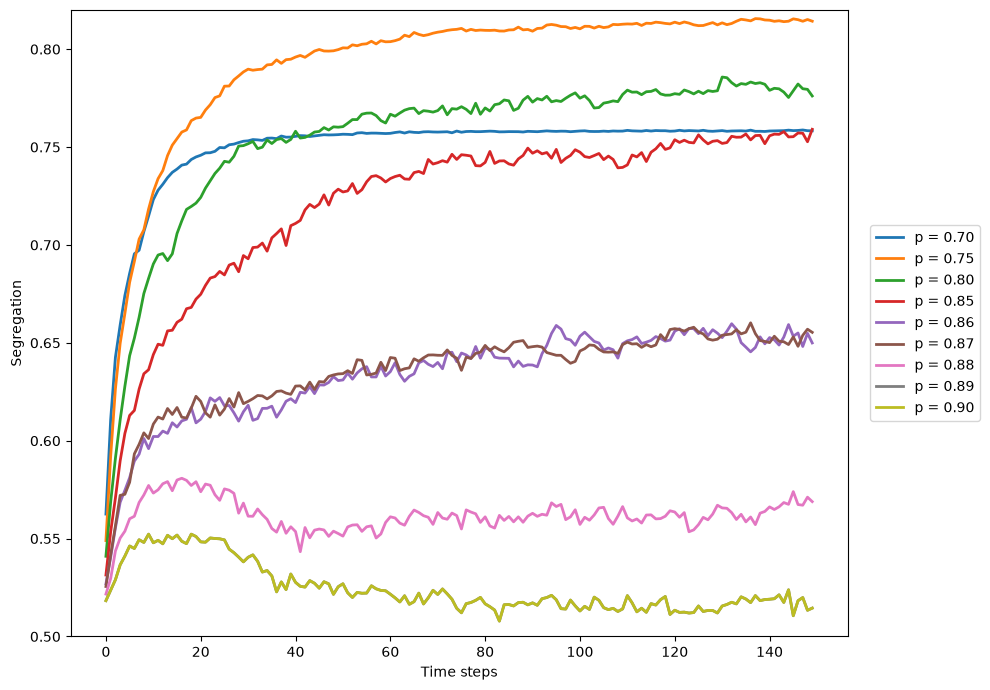

In [40]:
plt.figure(figsize=(10, 7))

for p in [0.7, 0.75, 0.8, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(segs, label='p = %.2f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.50, 0.82)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

### Figure 3: High satisfaction thresholds from $p=0.7$ to $0.9$

Segregation is high for $p=0.7$–$0.8$, with the highest curve at $p=0.75$. At $p=0.85$ and above, the final levels are generally lower and the curves fluctuate more. A possible reason is that many agents remain unhappy and continue moving.

p = 0.75, mean segregation = 0.8129
p = 0.76, mean segregation = 0.8222
p = 0.77, mean segregation = 0.8202
p = 0.78, mean segregation = 0.7999
p = 0.79, mean segregation = 0.8012
p = 0.80, mean segregation = 0.7883

Peak p = 0.76
Maximum segregation = 0.8221945208440674


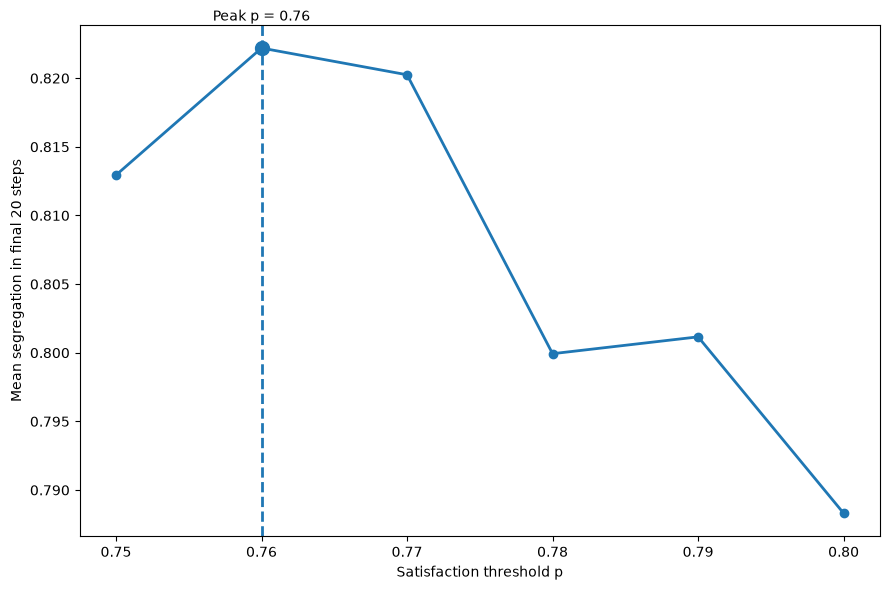

In [41]:
# Test p from 0.75 to 0.80
p_values = np.round(np.arange(0.75, 0.801, 0.01), 2)

seeds = range(5)
n_steps = 200
final_window = 20

mean_segs = []

for p in p_values:

    results = []

    for seed in seeds:

        np.random.seed(seed)

        grid = Schelling(n=100, p=p)

        segs = []

        for step in range(n_steps):
            grid.step()
            segs.append(grid.segregation())

        # Average segregation of the final 20 steps
        results.append(np.mean(segs[-final_window:]))

    # Average result from all seeds
    mean_segs.append(np.mean(results))

    print(f"p = {p:.2f}, "f"mean segregation = {np.mean(results):.4f}")

# Find the maximum
peak_index = np.argmax(mean_segs)

peak_p = p_values[peak_index]
peak_seg = mean_segs[peak_index]

print("\nPeak p =", peak_p)
print("Maximum segregation =", peak_seg)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(p_values, mean_segs, marker='o', linewidth=2)

# Mark the peak
plt.scatter(peak_p, peak_seg, s=100)

plt.axvline(peak_p, linestyle='--')

plt.text(peak_p, peak_seg + 0.002, f'Peak p = {peak_p:.2f}', ha='center')

plt.xlabel('Satisfaction threshold p')
plt.ylabel('Mean segregation in final 20 steps')

plt.xticks(p_values)

plt.tight_layout()
plt.show()

### Figure 4: Searching for the peak from $p=0.75$ to $0.80$

We tested $p$ from 0.75 to 0.80 in steps of 0.01. Each value was tested with five random seeds for 200 time steps. Segregation was averaged over the final 20 steps of each run, then across the five runs. Among the tested values, $p=0.76$ gives the highest mean segregation, about 0.8222.

## 6. Effect of the marriage parameter $m$ on clustering

With $p$ fixed at the calibrated value 0.76, we vary $m$ and measure the average size of connected pure-A and pure-B clusters (8-connected components via `scipy.ndimage.label`). The helper functions below run a simulation (`simulate`) and measure cluster sizes (`measure_clusters`). The first plot shows final grids for a single seed; the second averages over five seeds.

In [42]:
structure_8 = np.ones((3, 3), dtype=int)

def average_cluster_size(mask):
    _, count = ndimage.label(mask, structure=structure_8)
    return mask.sum() / count if count else 0.0

def simulate(p, m, n_steps, seed):
    np.random.seed(seed)
    grid = Schelling(n=100, p=p, m=m)
    for _ in range(n_steps):
        grid.step()
    return grid

def measure_clusters(grid):
    pure_a = (grid.array == 1) | (grid.array == 3)
    pure_b = (grid.array == 2) | (grid.array == 4)
    return average_cluster_size(pure_a), average_cluster_size(pure_b)

snapshot_p = 0.76
snapshot_steps = 150
snapshot_seed = 17

m_snapshot = np.round(np.arange(0.1, 1.0, 0.1), 1)
snapshot_results = []

for m in m_snapshot:
    grid = simulate(snapshot_p, m, snapshot_steps, snapshot_seed)
    a, b = measure_clusters(grid)

    snapshot_results.append((m, grid.array.copy(), a, b))

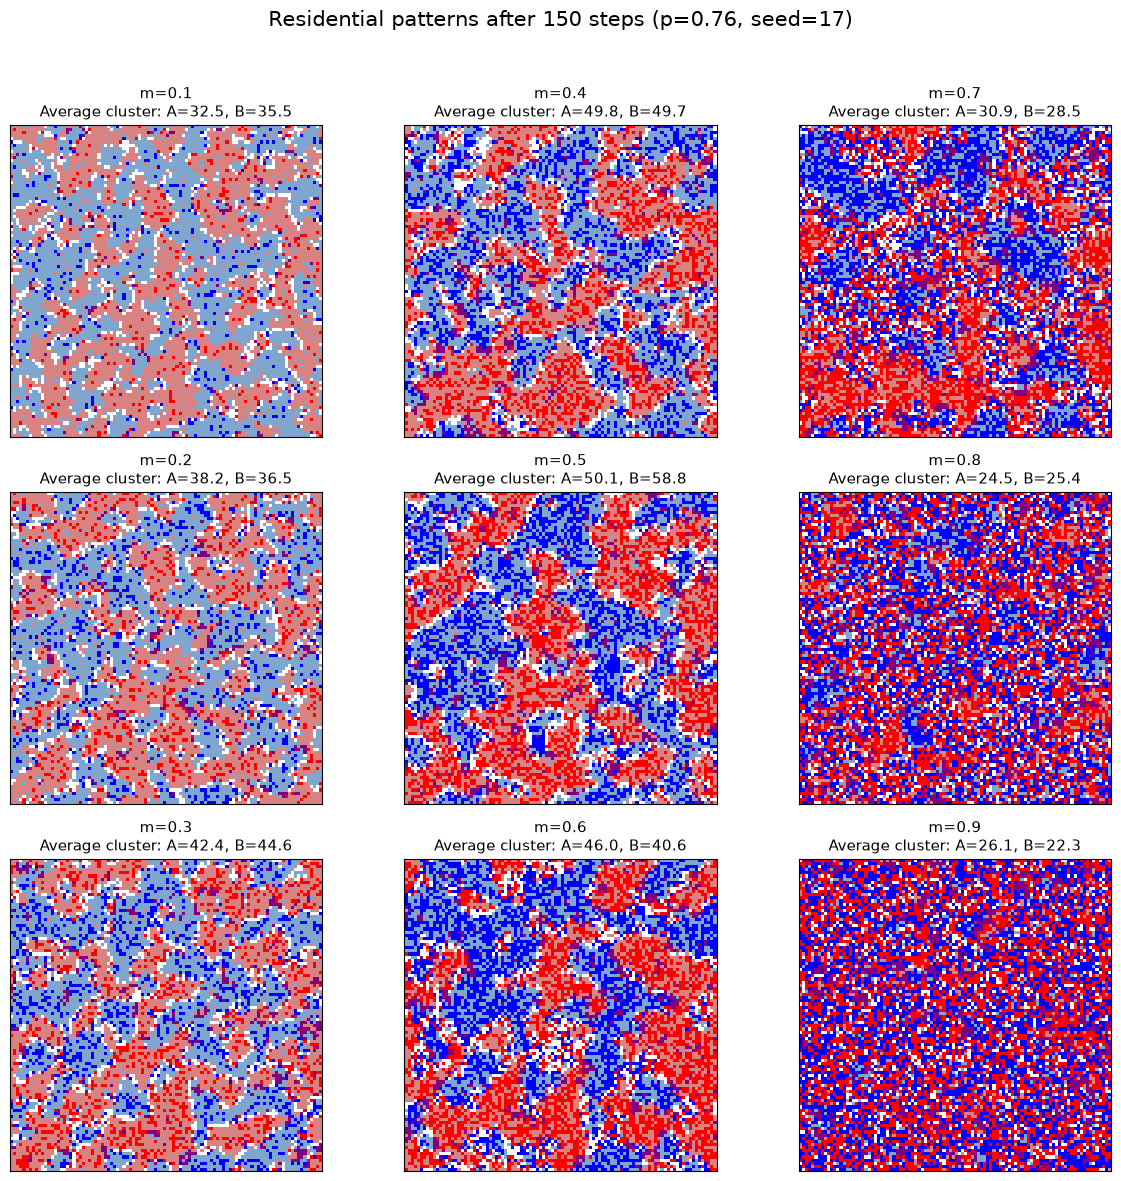

In [43]:
snapshot_cmap = ListedColormap([
    "white", "#D98282", "#7EA6CF",
    "red", "blue", "purple",
])

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (m, array, a, b) in zip(
    axes.T.flat, snapshot_results
):
    ax.imshow(array, cmap=snapshot_cmap, vmin=0, vmax=5, interpolation="nearest",)

    ax.set_title(f"m={m:.1f}\n" f"Average cluster: A={a:.1f}, B={b:.1f}", fontsize=11,)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(
    f"Residential patterns after {snapshot_steps} steps "
    f"(p={snapshot_p}, seed={snapshot_seed})",
    fontsize=15,
)

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

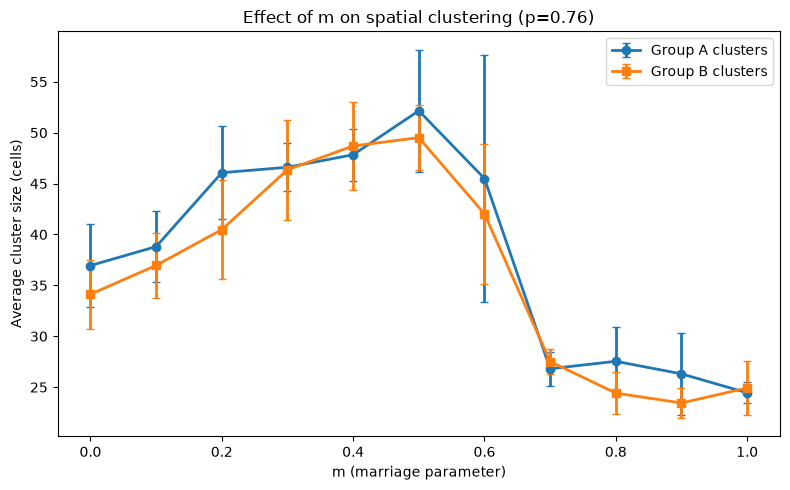

In [44]:
m_fig6 = np.round(np.arange(0.0, 1.01, 0.1), 1)
seeds_fig6 = range(5)
p_fig6 = 0.76
steps_fig6 = 150

# Dimensions: m, seed, A/B
results_fig6 = np.zeros((len(m_fig6), len(seeds_fig6), 2))

for i, m in enumerate(m_fig6):
    for j, seed in enumerate(seeds_fig6):
        grid = simulate(p_fig6, m, steps_fig6, seed)
        results_fig6[i, j] = measure_clusters(grid)

plt.figure(figsize=(8, 5))

for k, group in enumerate(['A', 'B']):
    values = results_fig6[:, :, k]
    plt.errorbar(
        m_fig6,
        values.mean(axis=1),
        yerr=values.std(axis=1),
        marker='o' if group == 'A' else 's',
        capsize=3,
        label=f'Group {group} clusters'
    )

plt.xlabel('m (marriage parameter)')
plt.ylabel('Average cluster size (cells)')
plt.title(f'Effect of m on spatial clustering (p={p_fig6})')
plt.legend()
plt.tight_layout()
plt.show()

### Effect of $m$ on spatial clustering

The first figure and the second figure show larger pure A and B clusters around $m=0.5$, followed by smaller clusters at higher values. We then measured average cluster size across five random seeds to examine this pattern. Both groups show a peak around $m=0.5$ and a clear decline between $m=0.6$ and $m=0.7$. The error bars show the standard deviation across seeds. Both figures use $p=0.76$ and 150 time steps.

Average cluster size is the total number of pure A or pure B cells divided by the number of clusters in that group. Connected cells, including diagonal neighbours, form one cluster. A larger value means larger connected areas.


Peak: m = 0.54, average cluster size = 57.07


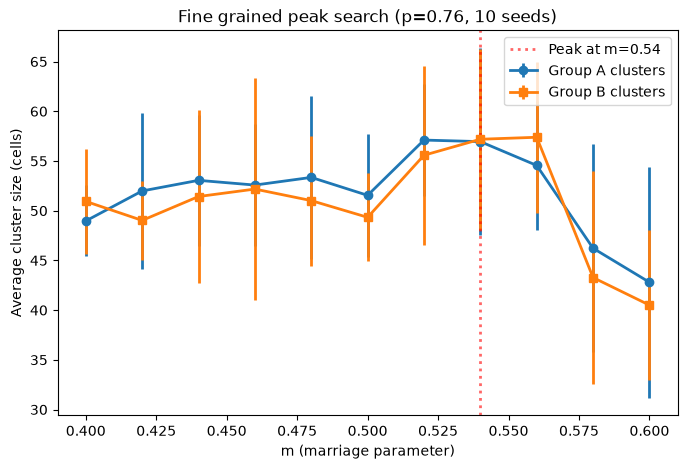

In [45]:
m_values_fine = np.round(np.arange(0.4, 0.61, 0.02), 2)  # 0.40, 0.42, 0.44, ..., 0.60 (11 points in total)
p_fixed = 0.76
n_steps = 150
seeds = range(10)

cluster_results_fine = {m: {'A': [], 'B': []} for m in m_values_fine}

for m in m_values_fine:
    for seed in seeds:
        np.random.seed(seed)
        grid = Schelling(n=100, p=p_fixed, m=m)
        for _ in range(n_steps):
            grid.step()
        pure_a = (grid.array == 1) | (grid.array == 3)
        pure_b = (grid.array == 2) | (grid.array == 4)
        cluster_results_fine[m]['A'].append(average_cluster_size(pure_a))
        cluster_results_fine[m]['B'].append(average_cluster_size(pure_b))

means_a_fine = [np.mean(cluster_results_fine[m]['A']) for m in m_values_fine]
means_b_fine = [np.mean(cluster_results_fine[m]['B']) for m in m_values_fine]
stds_a_fine = [np.std(cluster_results_fine[m]['A']) for m in m_values_fine]
stds_b_fine = [np.std(cluster_results_fine[m]['B']) for m in m_values_fine]

avg_combined_fine = [(a + b) / 2 for a, b in zip(means_a_fine, means_b_fine)]
peak_index_fine = np.argmax(avg_combined_fine)
peak_m_fine = m_values_fine[peak_index_fine]
print(f'Peak: m = {peak_m_fine}, average cluster size = {avg_combined_fine[peak_index_fine]:.2f}')

plt.figure(figsize=(8, 5))
plt.errorbar(m_values_fine, means_a_fine, yerr=stds_a_fine, marker='o', label='Group A clusters')
plt.errorbar(m_values_fine, means_b_fine, yerr=stds_b_fine, marker='s', label='Group B clusters')
plt.axvline(peak_m_fine, color='red', linestyle=':', alpha=0.6, label=f'Peak at m={peak_m_fine}')
plt.xlabel('m (marriage parameter)')
plt.ylabel('Average cluster size (cells)')
plt.title(f'Fine grained peak search (p={p_fixed}, {len(seeds)} seeds)')
plt.legend()
plt.show()

In [55]:
avg_combined_fine = [(a + b) / 2 for a, b in zip(means_a_fine, means_b_fine)]
diffs_fine = np.diff(avg_combined_fine)
steepest_index_fine = np.argmin(diffs_fine)
m_before = m_values_fine[steepest_index_fine]
m_after = m_values_fine[steepest_index_fine + 1]
print(f'Largest drop in the tested range: m={m_before:.2f} to m={m_after:.2f}')
print(f'Combined average cluster size falls from '
      f'{avg_combined_fine[steepest_index_fine]:.1f} to '
      f'{avg_combined_fine[steepest_index_fine + 1]:.1f} cells.'
)

Largest drop in the tested range: m=0.56 to m=0.58
Combined average cluster size falls from 56.0 to 44.7 cells.


### A closer look at the peak

Based on the previous results, we tested $m$ from 0.40 to 0.60 in steps of 0.02, using ten random seeds, to find the peak more closely. The average of the A and B results was highest at $m=0.54$, around 57.1 cells. The largest drop occurred between $m=0.56$ and $m=0.58$.

## 7. How $p$ changes the effect of $m$

### Comparing different satisfaction thresholds

The previous tests used a fixed threshold of $p=0.76$. We now compare $p=0.2$–$0.7$ to see whether the effect of $m$ changes with the satisfaction threshold. Separate plots for Groups A and B help us check whether both groups show similar trends.

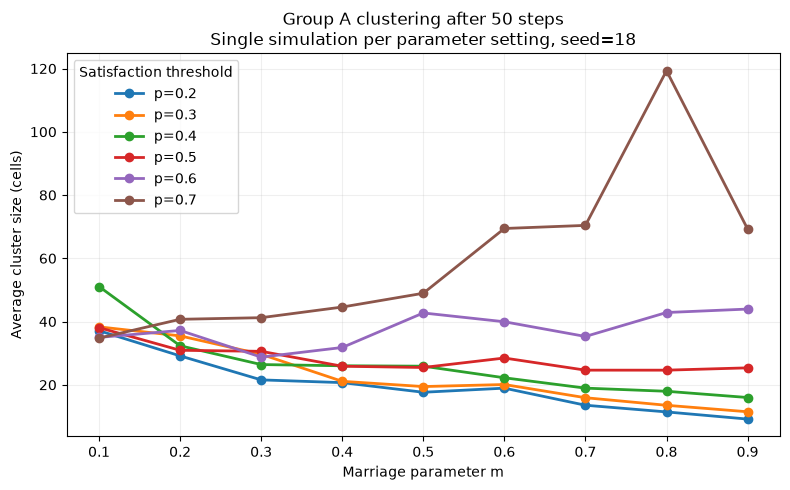

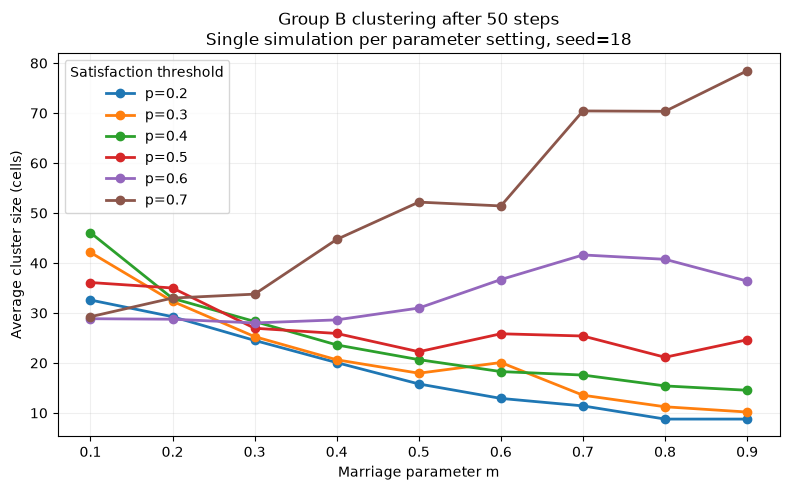

In [47]:
p_values = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
m_values = np.round(np.arange(0.1, 1.0, 0.1), 1)
n_steps = 50
seed = 18

shape = (len(p_values), len(m_values))
cluster_a_50 = np.zeros(shape)
cluster_b_50 = np.zeros(shape)

for i, p in enumerate(p_values):
    for j, m in enumerate(m_values):
        grid = simulate(p, m, n_steps, seed)
        cluster_a_50[i, j], cluster_b_50[i, j] = measure_clusters(grid)

def plot_cluster_low(
    group,
    p_levels=(0.2, 0.3, 0.4, 0.5, 0.6, 0.7),
    m_levels=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9),
    steps=50,
    seed_value=18,
):
    results = {
        "A": cluster_a_50,
        "B": cluster_b_50,
    }

    if group not in results:
        raise ValueError("Group must be 'A' or 'B'.")

    values = results[group]
    expected_shape = (len(p_levels), len(m_levels))

    if values.shape != expected_shape:
        raise ValueError(f"Results must have shape {expected_shape}.")

    fig, ax = plt.subplots(figsize=(8, 5))

    for i, p in enumerate(p_levels):
        ax.plot(
            m_levels,
            values[i],
            marker="o",
            label=f"p={p:.1f}",
        )

    ax.set_xlabel("Marriage parameter m")
    ax.set_ylabel("Average cluster size (cells)")
    ax.set_title(
        f"Group {group} clustering after {steps} steps\n"
        f"Single simulation per parameter setting, seed={seed_value}"
    )
    ax.set_xticks(m_levels)
    ax.legend(title="Satisfaction threshold")
    ax.grid(alpha=0.2)

    fig.tight_layout()
    plt.show()


plot_cluster_low("A")
plot_cluster_low("B")

After 50 time steps, both groups show an overall decrease in average cluster size as $m$ increases for $p=0.2$–$0.5$. At $p=0.6$, cluster size generally increases, with some fluctuations. At $p=0.7$, the overall increase is much stronger. These initial results suggest that the effect of $m$ depends on the satisfaction threshold $p$.

### Comparing higher satisfaction thresholds

Earlier time plots showed that segregation at lower thresholds became nearly steady within 50 steps. We use 100 steps for higher thresholds because they may need more time to adjust. This gives agents more time to move while keeping the calculation time reasonable.

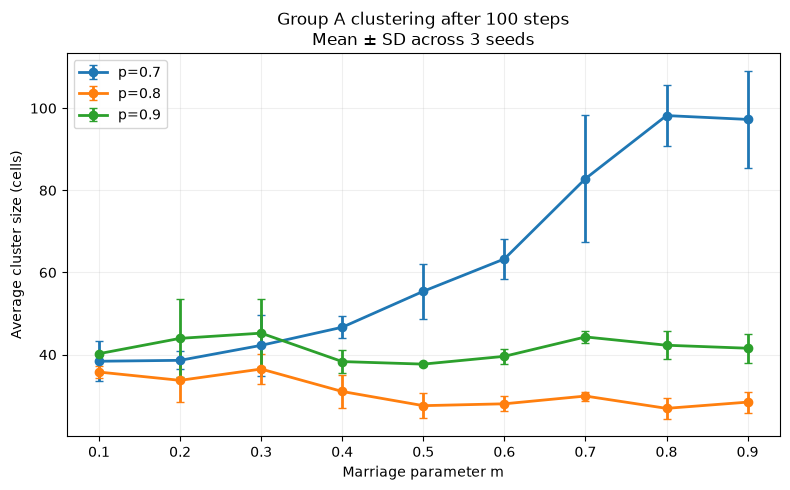

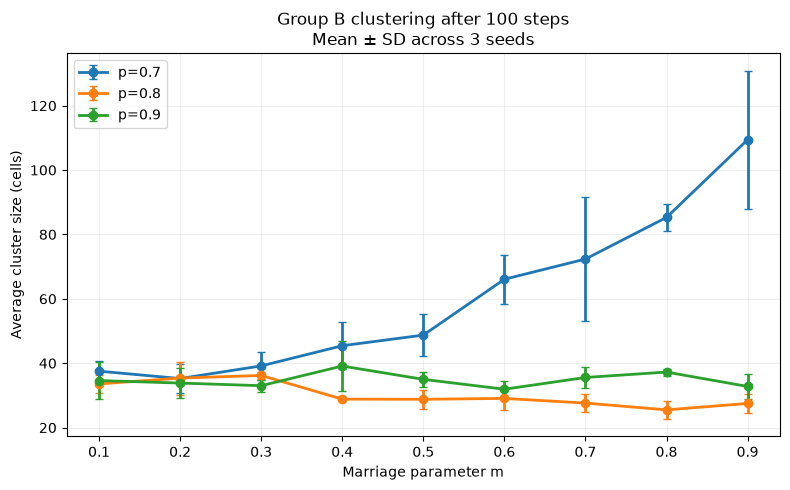

In [48]:
# High-p group: store parameters and results separately
p_high = [0.7, 0.8, 0.9]
m_high = np.round(np.arange(0.1, 1.0, 0.1), 1)
n_steps_high = 100
seeds_high = range(3)

# The three dimensions are p, m and random seed
shape_high = (len(p_high), len(m_high), len(seeds_high))
a_high = np.zeros(shape_high)
b_high = np.zeros(shape_high)

for i, p in enumerate(p_high):
    for j, m in enumerate(m_high):
        for k, trial_seed in enumerate(seeds_high):
            np.random.seed(trial_seed)
            grid = Schelling(n=100, p=p, m=m)

            for _ in range(n_steps_high):
                grid.step()

            pure_a = (grid.array == 1) | (grid.array == 3)
            pure_b = (grid.array == 2) | (grid.array == 4)

            a_high[i, j, k] = average_cluster_size(pure_a)
            b_high[i, j, k] = average_cluster_size(pure_b)

# Compute mean and standard deviation along the seed dimension
means_high = {
    'A': a_high.mean(axis=2),
    'B': b_high.mean(axis=2)
}
stds_high = {
    'A': a_high.std(axis=2, ddof=1),
    'B': b_high.std(axis=2, ddof=1)
}

# Plotting is separate, so plotting Group B does not require re-running the simulation
def plot_cluster_high(group):
    plt.figure(figsize=(8, 5))

    for i, p in enumerate(p_high):
        plt.errorbar(
            m_high,
            means_high[group][i],
            yerr=stds_high[group][i],
            marker='o',
            capsize=3,
            label=f'p={p:.1f}'
        )

    plt.xlabel('Marriage parameter m')
    plt.ylabel('Average cluster size (cells)')
    plt.title(
        f'Group {group} clustering after {n_steps_high} steps\n'
        f'Mean ± SD across {len(seeds_high)} seeds'
    )
    plt.xticks(m_high)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

plot_cluster_high('A')
plot_cluster_high('B')

After 100 time steps, both groups show a strong overall increase in average cluster size as $m$ increases at $p=0.7$. At $p=0.8$, cluster size generally decreases. At $p=0.9$, it changes relatively little, with no clear overall direction. These results suggest that the effect of $m$ still depends on $p$ at higher thresholds. The error bars show the standard deviation across three random seeds.

### How $p$ and $m$ affect cluster size

In these tests, the effect of increasing $m$ changes with $p$.

| $p$ | Tested $m$ range | Time steps | Main result for Groups A and B |
|---|---|---|---|
| 0.2–0.5 | 0.1–0.9 | 50 | Average cluster size generally decreases as $m$ increases. |
| 0.6 | 0.1–0.9 | 50 | Cluster size generally increases, with some fluctuations. |
| 0.7 | 0.1–0.9 | 100 | Cluster size shows a strong overall increase. |
| 0.76 | 0.0–1.0 | 150 | Clusters generally grow up to around $m=0.5$, then become smaller. |
| 0.8 | 0.1–0.9 | 100 | Cluster size generally decreases as $m$ increases. |
| 0.9 | 0.1–0.9 | 100 | Cluster size changes relatively little, with no clear overall direction. |

The closer test at $p=0.76$ found the highest combined A and B average at $m=0.54$, about 57.1 cells. The largest drop occurred between $m=0.56$ and $m=0.58$. These results show that a higher marriage parameter does not always lead to larger clusters.

### Analysis of $p$ and $m$

The results suggest that $p$ changes both the strength and the direction of the effect of $m$. In the 50-step tests, increasing $m$ from 0.1 to 0.9 generally produces smaller clusters at $p=0.2$–$0.5$. At $p=0.6$ and $p=0.7$, the direction changes and clusters generally become larger. This means that marriage can either weaken or strengthen pure-group clustering, depending on the satisfaction threshold.

At $p=0.76$, cluster size first increases and then falls as $m$ rises. The highest tested combined A and B average occurs at $m=0.54$, around 57.1 cells. Between $m=0.56$ and $m=0.58$, it drops from about 56.0 to 44.7 cells. A possible explanation is that AB households reduce the number of pure-group cells and change their connections. However, average cluster size alone cannot confirm this cause.

The 100-step tests show that a higher $p$ does not always produce larger clusters. At $m=0.8$–$0.9$, clusters are roughly 85–110 cells at $p=0.7$, but only about 25–30 cells at $p=0.8$. At $p=0.9$, changing $m$ has relatively little effect. Very strict requirements may keep agents moving and limit marriage opportunities, since only happy singles can marry. This could explain why increasing $m$ no longer leads to strong cluster growth.

## 8. AB households as connectors: effect of $m$

This is the core measure for our research question. An AB household counts as a **connector** if its 8 neighbours include at least one pure-A cell and at least one pure-B cell (see the formula in Section 2). For each run, the boundary fraction is averaged over the last 30 steps (sampled every 5 steps), then averaged across five seeds ($p = 0.76$, 150 steps).

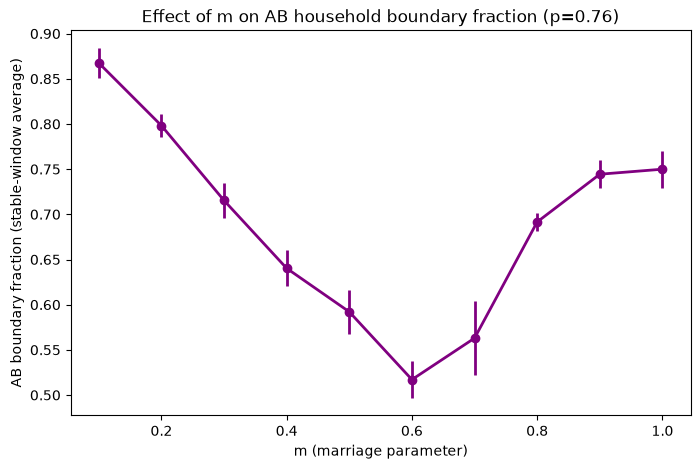

In [49]:
kernel = np.array([[1, 1, 1],
                    [1, 0, 1],
                    [1, 1, 1]])

def ab_boundary_fraction(grid):
    array = grid.array
    pure_a = (array == 1) | (array == 3)
    pure_b = (array == 2) | (array == 4)
    ab_mask = (array == 5)
    num_pure_a_neighbors = correlate2d(pure_a.astype(int), kernel, mode='same', boundary='wrap')
    num_pure_b_neighbors = correlate2d(pure_b.astype(int), kernel, mode='same', boundary='wrap')
    is_boundary = ab_mask & (num_pure_a_neighbors > 0) & (num_pure_b_neighbors > 0)
    n_ab = np.sum(ab_mask)
    n_boundary = np.sum(is_boundary)
    return (n_boundary / n_ab if n_ab > 0 else np.nan), n_ab

def run_and_measure_boundary(p, m, n_steps=150, sample_last_n=30, sample_every=5, seed=0):
    """Run n_steps, sample the boundary fraction every sample_every steps within the last sample_last_n steps, and return the average."""
    np.random.seed(seed)
    grid = Schelling(n=100, p=p, m=m)
    fracs = []
    for t in range(n_steps):
        grid.step()
        if t >= n_steps - sample_last_n and (n_steps - 1 - t) % sample_every == 0:
            frac, n_ab = ab_boundary_fraction(grid)
            if not np.isnan(frac):
                fracs.append(frac)
    return np.mean(fracs) if fracs else np.nan

m_values = np.round(np.arange(0.1, 1.01, 0.1), 2)  # 0.1 to 1.0 in steps of 0.1 (10 points)
p_fixed = 0.76
seeds = range(5)

boundary_results = {m: [] for m in m_values}

for m in m_values:
    for seed in seeds:
        frac = run_and_measure_boundary(p_fixed, m, seed=seed)
        boundary_results[m].append(frac)

means = [np.nanmean(boundary_results[m]) for m in m_values]
stds = [np.nanstd(boundary_results[m]) for m in m_values]

plt.figure(figsize=(8, 5))
plt.errorbar(m_values, means, yerr=stds, marker='o', color='purple')
plt.xlabel('m (marriage parameter)')
plt.ylabel('AB boundary fraction (stable-window average)')
plt.title(f'Effect of m on AB household boundary fraction (p={p_fixed})')
plt.show()

### AB households near both groups

We look at the eight cells around each AB household. If it has both a pure A neighbour and a pure B neighbour, we call it a boundary household. We divide this number by the total number of AB households. For example, 0.52 means that 52% of AB households are next to both groups.

At $p=0.76$, this share falls from about 0.87 at $m=0.1$ to 0.52 at $m=0.6$, then rises to 0.75 at $m=1.0$.

The larger pure A and B clusters around medium $m$ may explain part of this fall. Some AB households may then have mainly one group nearby, so fewer meet the boundary condition.

Above $m=0.6$, the fraction rises again. Smaller pure clusters at higher $m$ may make it easier for AB households to have neighbours from both groups.

## 9. Effect of openness

We now fix $p = 0.76$ and $m = 0.54$ (the clustering peak from Section 5) and give every agent the same openness using `Schelling(..., fixed_openness=...)`. Openness is swept from 0.1 to 1.0 with five seeds per value.

/var/folders/r1/r7fnsgws2c785bzdny_5n1cr0000gn/T/ipykernel_42509/57190576.py:45: RuntimeWarning: Mean of empty slice
  means = [np.nanmean(boundary_results[ov]) for ov in openness_values]
/Users/lucen/UWA learning/CITS 4403/vene/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


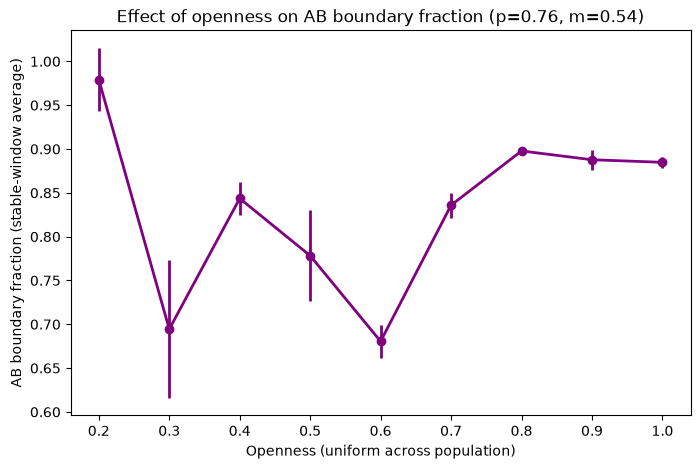

In [ ]:
kernel = np.array([[1, 1, 1],
                    [1, 0, 1],
                    [1, 1, 1]])

def ab_boundary_fraction(grid):
    array = grid.array
    pure_a = (array == 1) | (array == 3)
    pure_b = (array == 2) | (array == 4)
    ab_mask = (array == 5)
    num_pure_a_neighbors = correlate2d(pure_a.astype(int), kernel, mode='same', boundary='wrap')
    num_pure_b_neighbors = correlate2d(pure_b.astype(int), kernel, mode='same', boundary='wrap')
    is_boundary = ab_mask & (num_pure_a_neighbors > 0) & (num_pure_b_neighbors > 0)
    n_ab = np.sum(ab_mask)
    n_boundary = np.sum(is_boundary)
    return (n_boundary / n_ab if n_ab > 0 else np.nan), n_ab

def run_and_measure_boundary(p, m, openness_value, n_steps=150, sample_last_n=30, sample_every=5, seed=0):
    np.random.seed(seed)
    grid = Schelling(n=100, p=p, m=m, fixed_openness=openness_value)
    fracs = []
    for t in range(n_steps):
        grid.step()
        if t >= n_steps - sample_last_n and (n_steps - 1 - t) % sample_every == 0:
            frac, n_ab = ab_boundary_fraction(grid)
            if not np.isnan(frac):
                fracs.append(frac)
    return np.mean(fracs) if fracs else np.nan

openness_values = np.round(np.arange(0.1, 1.01, 0.1), 2)  # 0.1 to 1.0 in steps of 0.1 (10 points)
p_fixed = 0.76
m_fixed = 0.54
seeds = range(5)

boundary_results = {ov: [] for ov in openness_values}

for ov in openness_values:
    for seed in seeds:
        frac = run_and_measure_boundary(p_fixed, m_fixed, ov, seed=seed)
        boundary_results[ov].append(frac)

means = []
stds = []

for ov in openness_values:
    values = np.asarray(boundary_results[ov], dtype=float)
    valid = values[np.isfinite(values)]

    means.append(valid.mean() if valid.size > 0 else np.nan)
    stds.append(valid.std(ddof=0) if valid.size >= 2 else np.nan)

    print(f"Openness={ov:.1f}: "f"{valid.size}/{len(seeds)} valid runs")

plt.figure(figsize=(8, 5))
plt.errorbar(openness_values, means, yerr=stds, marker='o', color='purple')
plt.xlabel('Openness (uniform across population)')
plt.ylabel('AB boundary fraction (late-window average)')
plt.title(f'Effect of openness on AB boundary fraction (p={p_fixed}, m={m_fixed})')
plt.show()

### Effect of openness on AB neighbours

This plot shows how openness affects the share of AB households with both pure A and pure B neighbours. We keep $p=0.76$ and $m=0.54$ fixed. The error bars show variation across random seeds.

The share goes up and down between openness 0.2 and 0.6. It then rises from about 0.68 at 0.6 to 0.90 at 0.8, and stays near 0.89 at 0.8–1.0. This shows that increasing openness does not always increase the boundary fraction.

Openness affects both marriage choices and satisfaction with neighbours. At openness 0.8–1.0, single agents and AB households with occupied neighbours can already meet the satisfaction threshold. They can stay in mixed areas, which may help explain the high and nearly steady boundary fraction.

## 10. Interaction between openness and $m$

We repeat the openness sweep for ten values of $m$ (0.1–1.0), with three seeds per combination (300 runs, $p = 0.76$, 150 steps). The first cell runs the simulations; the second draws the heatmap.

In [52]:
kernel = np.array([[1, 1, 1],
                    [1, 0, 1],
                    [1, 1, 1]])

def ab_boundary_fraction(grid):
    array = grid.array
    pure_a = (array == 1) | (array == 3)
    pure_b = (array == 2) | (array == 4)
    ab_mask = (array == 5)
    num_pure_a_neighbors = correlate2d(pure_a.astype(int), kernel, mode='same', boundary='wrap')
    num_pure_b_neighbors = correlate2d(pure_b.astype(int), kernel, mode='same', boundary='wrap')
    is_boundary = ab_mask & (num_pure_a_neighbors > 0) & (num_pure_b_neighbors > 0)
    n_ab = np.sum(ab_mask)
    n_boundary = np.sum(is_boundary)
    return (n_boundary / n_ab if n_ab > 0 else np.nan), n_ab

def run_and_measure_boundary_openness_m(p, m, openness_value, n_steps=150, sample_last_n=30, sample_every=5, seed=0):
    np.random.seed(seed)

    grid = Schelling(n=100, p=p, m=m, fixed_openness=openness_value)

    fracs = []

    for t in range(n_steps):
        grid.step()

        if (t >= n_steps - sample_last_n and (n_steps - 1 - t) % sample_every == 0):
            frac, _ = ab_boundary_fraction(grid)

            if not np.isnan(frac):
                fracs.append(frac)

    return np.mean(fracs) if fracs else np.nan

m_values_full = np.round(np.arange(0.1, 1.01, 0.1), 2)         # 0.1 to 1.0: 10 lines
openness_values_full = np.round(np.arange(0.1, 1.01, 0.1), 2)  # 0.1 to 1.0: 10 points per line
p_fixed = 0.76
seeds = range(3)

results_full = []
for m in m_values_full:
    for openness in openness_values_full:
        for seed in seeds:
            frac = run_and_measure_boundary_openness_m(p_fixed, m, openness, seed=seed)
            results_full.append({'m': m, 'openness': openness, 'seed': seed, 'boundary_frac': frac})

df_full = pd.DataFrame(results_full)
summary_full = df_full.groupby(['m', 'openness'])['boundary_frac'].agg(['mean', 'std']).reset_index()

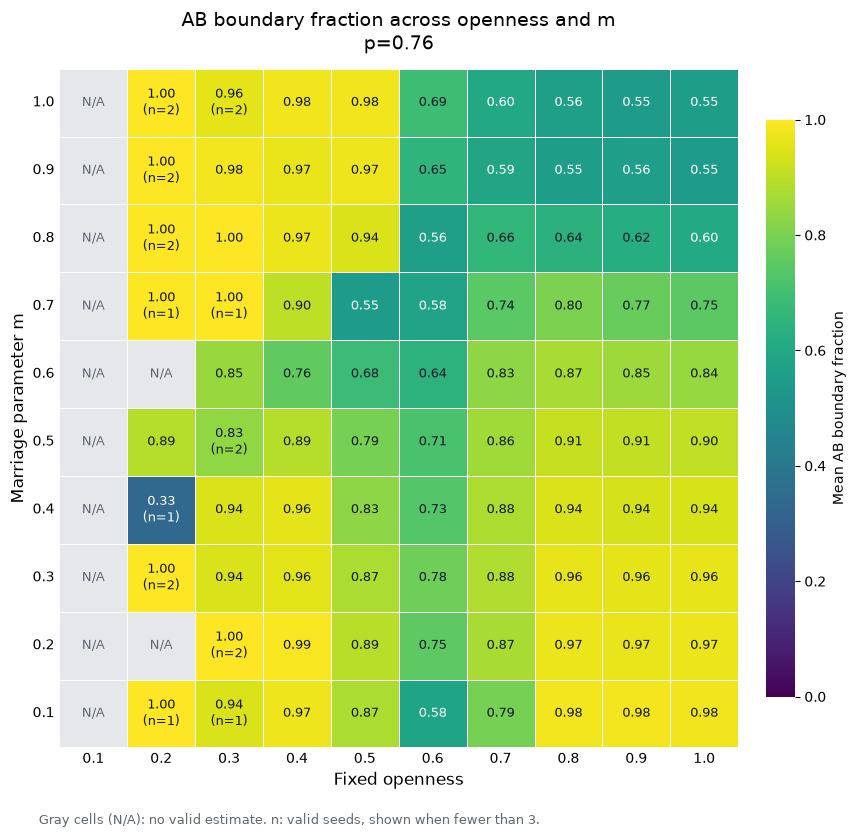

In [53]:


# Keep the complete parameter grid.
levels = np.round(np.arange(0.1, 1.01, 0.1), 2)

heatmap_data = (
    summary_full
    .pivot(index="m", columns="openness", values="mean")
    .reindex(index=levels, columns=levels)
)

# Count distinct seeds with valid results.
valid_counts = (
    df_full.loc[df_full["boundary_frac"].notna()]
    .groupby(["m", "openness"])["seed"]
    .nunique()
    .unstack("openness")
    .reindex(index=levels, columns=levels)
    .fillna(0)
    .astype(int)
)

expected_seeds = int(df_full["seed"].nunique())
heatmap_cmap = plt.get_cmap("viridis")
missing_color = "#E5E7EB"

fig, ax = plt.subplots(figsize=(10, 8.5))

sns.heatmap(
    heatmap_data,
    ax=ax,
    mask=heatmap_data.isna(),
    annot=False,
    cmap=heatmap_cmap,
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.6,
    linecolor="white",
    xticklabels=[f"{x:.1f}" for x in levels],
    yticklabels=[f"{y:.1f}" for y in levels],
    cbar_kws={
        "label": "Mean AB boundary fraction",
        "shrink": 0.85,
        "pad": 0.03,
    },
)

# Label missing cells and adjust text contrast.
for i in range(len(levels)):
    for j in range(len(levels)):
        value = heatmap_data.iloc[i, j]

        if np.isnan(value):
            ax.add_patch(
                Rectangle(
                    (j, i), 1, 1,
                    facecolor=missing_color,
                    edgecolor="white",
                    linewidth=0.6,
                )
            )
            label = "N/A"
            text_color = "#606770"
        else:
            label = f"{value:.2f}"
            count = valid_counts.iloc[i, j]

            if count < expected_seeds:
                label += f"\n(n={count})"

            r, g, b, _ = heatmap_cmap(float(value))
            luminance = 0.2126*r + 0.7152*g + 0.0722*b
            text_color = "#111827" if luminance > 0.55 else "white"

        ax.text(
            j + 0.5,
            i + 0.5,
            label,
            ha="center",
            va="center",
            color=text_color,
            fontsize=9,
        )

ax.invert_yaxis()
ax.set_xlabel("Fixed openness", fontsize=12)
ax.set_ylabel("Marriage parameter m", fontsize=12)
ax.set_title(
    "AB boundary fraction across openness and m\n"
    "p=0.76",
    fontsize=14,
    pad=14,
)
ax.tick_params(axis="both", labelrotation=0, length=0)

fig.text(
    0.12, 0.035,
    "Gray cells (N/A): no valid estimate. "
    f"n: valid seeds, shown when fewer than {expected_seeds}.",
    fontsize=9,
    color="#606770",
)

fig.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

### How openness and $m$ affect AB neighbours

We keep $p=0.76$ fixed and test different combinations of openness and $m$. Each setting uses 150 time steps and three random seeds. Openness stays fixed throughout each run, including for new agents.

Each cell shows the average share of AB households with at least one pure A neighbour and one pure B neighbour among their eight surrounding cells, using measurements from the final part of each run.

- **Rows** show $m$; **columns** show openness.
- **Yellow** means a higher share. For example, 0.91 means about 91%.
- **N/A** means no valid fraction could be calculated. **n=1** or **n=2** shows how many of the three runs had valid results.

At openness 0.8–1.0, the share generally falls as $m$ increases. It is about 90%–98% at $m=0.1$–$0.5$, compared with 55%–64% at $m=0.8$–$1.0$.

**The main finding is that the effect of openness depends on $m$. The same increase in openness can produce opposite results.**

At openness 0.8–1.0, the share is about 90%–98% at $m=0.1$–$0.5$, compared with 55%–64% at $m=0.8$–$1.0$. In this range, higher $m$ generally means a lower share of AB households next to both groups.

Raising openness from 0.5 to 0.8 increases the share from 55% to 80% at $m=0.7$, but lowers it from 98% to 56% at $m=1.0$. Therefore, increasing openness or $m$ alone does not always raise the boundary fraction. Their effects need to be considered together.

These results describe the neighbours of existing AB households. AB household counts are also needed to assess overall mixing.

## 11. Summary and limitations

**Summary of findings**

- **Calibration.** Segregation peaks at $p \approx 0.76$, so this value is used throughout the analysis.
- **Clustering.** At $p = 0.76$, increasing $m$ first consolidates pure-group territory into larger clusters (peak near $m = 0.54$) and then fragments it sharply between $m = 0.56$ and $0.58$. The direction of the effect of $m$ depends on $p$.
- **Connectors vs $m$.** The share of AB households that border both groups is lowest (about 0.52) at $m \approx 0.6$, close to where pure-group territory is most consolidated.
- **Openness.** The effect of openness is non-monotonic. Once openness reaches the threshold $p$, singles and AB households are satisfied whoever their neighbours are, and the boundary fraction stays high (about 0.89).
- **Interaction.** Openness and $m$ interact: the same increase in openness can raise the boundary fraction at one value of $m$ and lower it at another. High $m$ with high openness gives the lowest share of connectors (about 0.55–0.64).

**Limitations and next steps**

- Several sweeps use only one to five seeds, so small differences between neighbouring parameter values may be noise.
- The boundary fraction describes only the AB households that exist; it should be paired with the number of AB households to judge overall mixing.
- The cluster-size explanations are plausible mechanisms rather than demonstrated causes.
- Results are for a single grid size ($100 \times 100$) and a fixed AB-neighbour weight of 1.5.